# DINGO: imaging reference and R+C MCMC

First inspect a calibrated F150W PySersic fit, then set the DINGO geometry and starting values yourself. The imaging block is a reference: it does not automatically set a gas center, inclination prior or velocity.

Use the **grism** kernel. The existing three-file R+C model is unchanged, with intrinsic dispersion zero. A numerical `fixed_x0`, `fixed_y0` or `fixed_inclination` holds that parameter fixed; `None` samples it with its stated prior. Corner plots contain only sampled parameters.

In [14]:
from pathlib import Path
import os
import sys
import logging
import importlib
import matplotlib.pyplot as plt
from IPython.display import display

# Change these paths on another computer. No saved fits are read from them.
REPO = Path("/home/aakavan/kinematics/grism-kinematics")
DATA_DIR = REPO / "data"
EDR_DIR = Path("/home/aakavan/EDR_data")
SOURCE_ID = 6170  # Used by both the imaging reference and DINGO
CALIBRATION_DIR = REPO.parent / "grism_cal"
OUTPUT_ROOT = REPO.parent / "field_kinematics/edr_kinematics/PaA/dingo_runs"

sys.path.insert(0, str(REPO))
os.environ["GRISM_CAL_DIR"] = str(CALIBRATION_DIR)
# Keep warnings visible; progress bars report the sampling steps.
logging.getLogger("dingo.fitting").setLevel(logging.WARNING)
from dingo import simple_mcmc as sm
sm = importlib.reload(sm)

print("Code:", sm.__file__)
print("Output root:", OUTPUT_ROOT)

Code: /home/aakavan/kinematics/grism-kinematics/dingo/simple_mcmc.py
Output root: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs


## 0. PySersic imaging reference

Like `master_run_Paalpha.ipynb`, this extracts **calibrated F150W SCI and ERR mosaic cutouts**. It fits one PSF-convolved Sérsic component with free index $n$ and a constant sky level. The nonlinear legacy `image.fits` is not fitted. The actual image appears before sampling; afterward, the image and model show the fitted center in **zero-based imaging pixels**, followed by PySersic's standard corner plot and parameter table. No residual panel is displayed.

`IMAGING_CUTOUT_SIZE` is the native mosaic box width (101 pixels is approximately 3.03 arcsec). `IMAGING_FIT_RADIUS` controls the circular fitted region in arcseconds; reduce it if an edge neighbour contaminates the fit. Inclination is derived from axis ratio, and both $q_0=0$ and $q_0=0.2$ are reported.

Four PySersic chains run in a separate JAX worker with progress and checkpoints. Matching saved fits are reused. Set `REFIT_IMAGING=True` to make a fresh fit, including after changing the imaging settings; earlier fits are preserved. The center table also reports sky coordinates and, when a matching native exposure is available, an explicitly **approximate** R/C coordinate reference. No result is automatically applied to DINGO.

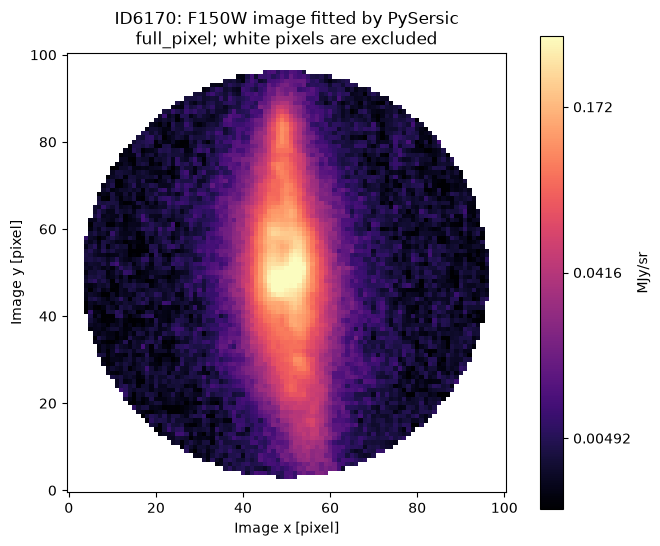

ID6170: F150W PySersic, 101×101 pixels, 1.4 arcsec fitting radius. Four chains per selected variant (full_pixel).
Imaging sampling: 1000 warmup + 2000 retained draws per chain.
/home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/morph_fits/F150W_reference/fit_001
/home/aakavan/anaconda3/envs/grism/lib/python3.12/site-packages/arviz/__init__.py:110: MigrationWarning: arviz.InferenceData is no longer available on the arviz package; ArviZ now uses xarray's DataTree for the same role. See the migration guide: https://python.arviz.org/en/latest/user_guide/migration_guide.html#datatree
  warnings.warn(
/home/aakavan/anaconda3/envs/grism/lib/python3.12/site-packages/pysersic/pysersic.py:719: UserWarning: More than 70 percent of input image is masked. Is this correct? (Pysersic treats True/1 as masked; you may need to flip your boolean array.)
  warnings.warn(
/home/aakavan/anaconda3/envs/grism/lib/python3.12/site-packages/pysersic/pysersic.py:75: UserWarning: A JAX ar

PySersic warmup / chain:   0%|          | 0/1000 [00:00<?, ?step/s]

PySersic draws / chain:   0%|          | 0/2000 [00:00<?, ?step/s]

{"output": "/home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/morph_fits/F150W_reference/fit_001/full_pixel", "diagnostics": {"convergence_gate_passed": true, "chains": 4, "draws_per_chain": 2000, "gate": "Four chains; every rank Rhat < 1.01, bulk/tail ESS >= 400; no divergences; BFMI >= .3. Maximum tree depth is an efficiency warning. Passing is necessary, not proof of scientific adequacy.", "all_diagnostics_finite": true, "divergences": 0, "max_depth_fraction": 0.0, "mean_acceptance": 0.9420481830972463, "mean_leapfrog_steps": 10.59, "sampling_warnings": [], "max_rank_rhat": 1.0012371424474378, "min_bulk_ess": 5161.096615610558, "min_tail_ess": 4702.859003359953, "bfmi_by_chain": [1.0200958138776417, 1.0401922091012563, 1.0619446625897377, 1.0399641806144402]}, "orientation_parameterization_ok": true, "radius_boundary_fraction": 0.0, "residual_rms": 2.420486069729346}


,fit,completed,ready,max_Rhat,min_bulk_ESS,min_tail_ESS,divergences,q_median,residual_RMS,parameter_checks_passed,note
0,full_pixel,True,True,1.001237,5161.096616,4702.859003,0,0.308206,2.420486,True,Inspect residuals; passing sampler checks does...


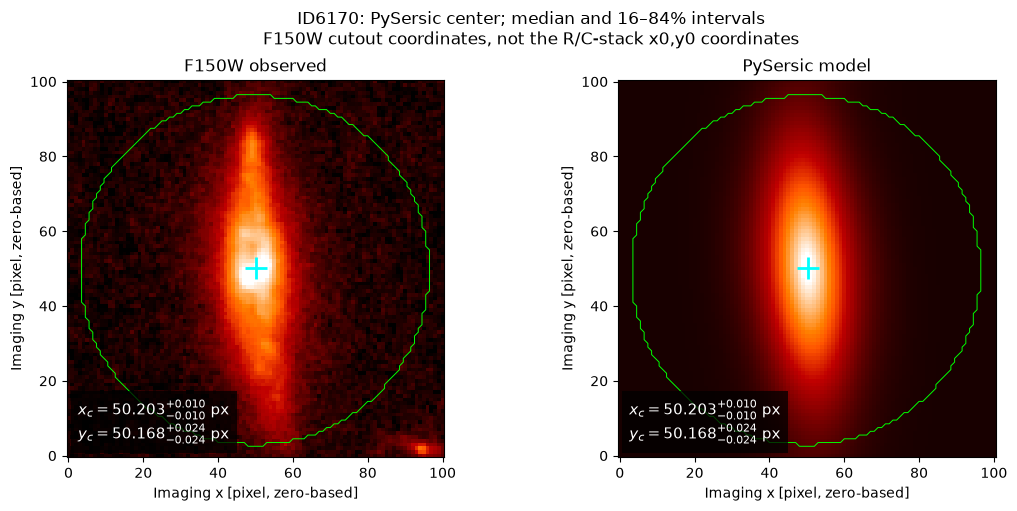

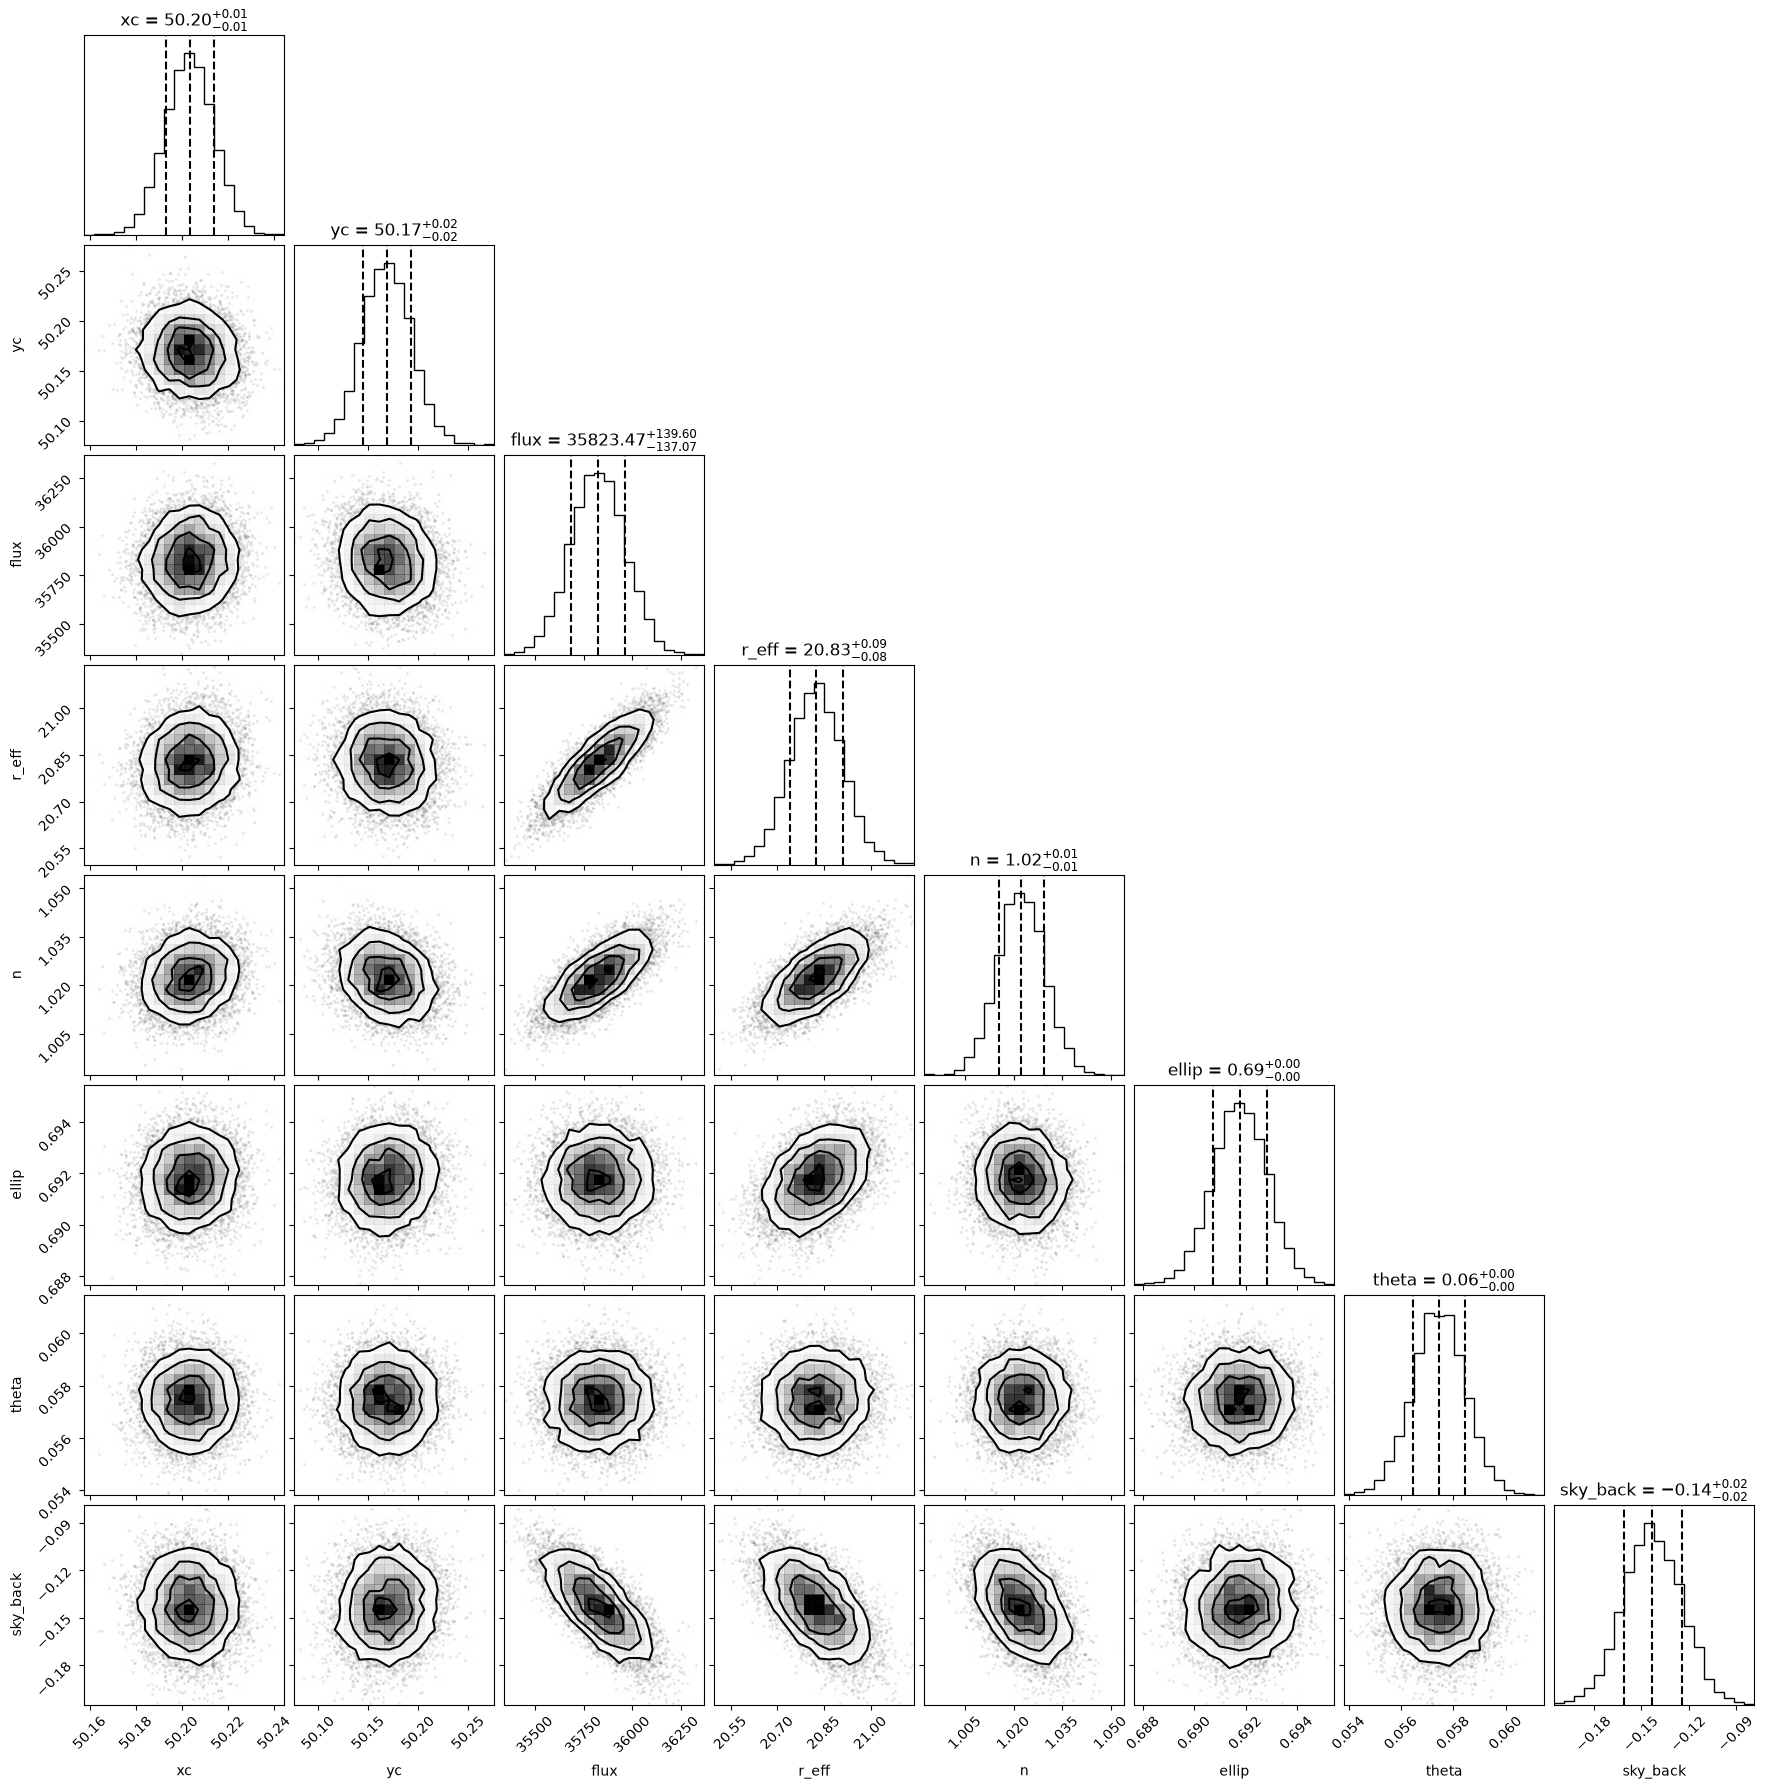

,meaning,median,minus_1sigma,plus_1sigma,p16,p84,unit
parameter,,,,,,,
xc,Center x,50.203275,0.010261,0.010427,50.193014,50.213702,pixel
yc,Center y,50.168473,0.024168,0.024176,50.144305,50.192649,pixel
flux,Total Sérsic flux,35823.469597,137.066669,139.601023,35686.402928,35963.070621,normalized image sum
r_eff,Effective radius,20.825110,0.083552,0.085355,20.741558,20.910465,pixel
n,Sérsic index,1.022392,0.007028,0.007064,1.015365,1.029456,
ellip,Ellipticity = 1 − b/a,0.691794,0.001050,0.001061,0.690745,0.692855,
theta,PySersic angle,0.057454,0.000987,0.000983,0.056467,0.058437,rad
sky_back,Constant sky level,-0.142980,0.017881,0.018824,-0.160861,-0.124155,normalized image value
q,Axis ratio b/a (derived),0.308206,0.001061,0.001050,0.307145,0.309255,


,median_deg,minus_1sigma_deg,plus_1sigma_deg,incompatible_fraction,status
q0,,,,,
0.0,72.048878,0.063245,0.06387,0.0,compatible
0.2,76.152618,0.083020,0.08405,0.0,compatible


PySersic report: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/morph_fits/F150W_reference/fit_001/pysersic_6170_info.cat


,median,minus_1sigma,plus_1sigma,p16,p84,unit,meaning
parameter,,,,,,,
image_xc,50.203275,1.026079e-02,1.042735e-02,50.193014,50.213702,pixel,F150W cutout x center; not a DINGO pixel coord...
image_yc,50.168473,2.416798e-02,2.417600e-02,50.144305,50.192649,pixel,F150W cutout y center; not a DINGO pixel coord...
ra,63.942756,9.519928e-08,9.379831e-08,63.942756,63.942756,deg,Fitted centroid right ascension
dec,-24.171425,2.013852e-07,2.014710e-07,-24.171425,-24.171425,deg,Fitted centroid declination
east_offset,-0.014251,3.126696e-04,3.080681e-04,-0.014564,-0.013943,arcsec,East of source catalog position
north_offset,0.017300,7.249867e-04,7.252957e-04,0.016575,0.018025,arcsec,North of source catalog position
nominal_dingo_x0,40.024130,8.209328e-03,8.320422e-03,40.015921,40.032451,pixel,Approximate DINGO x0; catalog anchored at cuto...
nominal_dingo_y0,40.356831,9.570029e-03,9.585556e-03,40.347261,40.366417,pixel,Approximate DINGO y0; catalog anchored at cuto...


Zero-based imaging pixels: x=column, y=row. Do not copy them directly into DINGO.
Intervals include centroid posterior uncertainty only; astrometric systematics and stellar/gas offsets are excluded.
Nominal DINGO coordinates anchor the catalog at (40,40) using a native detector WCS; no R/C stack registration uncertainty is included.
PySersic reference saved in: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/morph_fits/F150W_reference/fit_001
Imaging is a reference for your manual settings; no DINGO values or priors were changed.


In [15]:
from dingo import imaging_reference as ir
ir = importlib.reload(ir)

IMAGING_CUTOUT_SIZE = 101  # F150W mosaic pixels, not R/C pixels; use an odd width
IMAGING_FIT_RADIUS = 1.4   # Arcseconds; must fit inside the cutout
REFIT_IMAGING = False     # True makes a fresh PySersic fit; old fits are preserved

imaging = ir.fit_reference(
    SOURCE_ID,
    data_dir=DATA_DIR,
    output_root=OUTPUT_ROOT,
    edr_dir=EDR_DIR,
    cutout_size=IMAGING_CUTOUT_SIZE,
    fit_radius=IMAGING_FIT_RADIUS,
    warmup=1000,
    draws=2000,
    device="cuda",       # Or "cpu"
    refit=REFIT_IMAGING,
)

## 1. Choose DINGO geometry and starting values

Use the PySersic block above as a reference, then edit these arguments manually. **Its native imaging pixels are not R/C pixels.** The optional nominal R/C center accounts for the detector WCS but assumes the catalog position is the stack midpoint; it does not measure the old stacks' registration error.

This setup currently fixes `x0=y0=40` in R/C pixels and samples inclination with the explicit prior $75^\circ\pm5^\circ$. Change the fixed coordinates if justified by your inspection. Set `fixed_x0=None` and `fixed_y0=None` to sample the center using `CENTER_MEAN` and `CENTER_SIGMA_PIXELS`; the center prior is ignored for fixed coordinates.

The values below are assumptions, not automatically copied from PySersic. In particular, imaging does not measure a rotation velocity. `start_velocity` remains your explicit asymptotic $V_\infty$ starting value.

Use a new `RUN_NAME` for each experiment. With `overwrite=True`, rerunning this preparation cell replaces that named DINGO run. PySersic results live separately under the source's `morph_fits` directory.

In [ ]:
CENTER_MEAN = (40.0, 40.0)  # Assumed center in R/C stack pixels; check against the image
CENTER_SIGMA_PIXELS = 1.0    # 1-sigma per coordinate; change to 2.0 for a separate comparison
# RUN_NAME = f"gaussian_center_s{CENTER_SIGMA_PIXELS:g}_i75_centered_v450"
RUN_NAME = "fixed_xy40_sampled_i_test1"

run = sm.prepare(
    SOURCE_ID,
    data_dir=DATA_DIR,
    output_root=OUTPUT_ROOT,
    run_name=RUN_NAME,
    overwrite=True,
    device="cuda",                 # or "cpu"

    fixed_x0=40.0,                 # Fixed R/C x pixel; None samples with center prior
    fixed_y0=40.0,                 # Fixed R/C y pixel; None samples with center prior
    start_center=CENTER_MEAN,
    center_mean=CENTER_MEAN,
    center_sigma=CENTER_SIGMA_PIXELS,

    fixed_inclination=None,        # Sample i with the Gaussian prior below
    start_inclination=75.0,
    inclination_mean=75.0,
    inclination_sigma=5.0,         # 1-sigma, degrees

    start_velocity=450.0,          # Sampled V_inf, km/s
    start_turnover=10.09,          # Sampled R_t, pixels
    start_pa=286.64,               # Sampled cutout orientation, degrees
    start_offset=(1.0625, 0.2852),  # Sampled R registration dx,dy, pixels
    max_velocity=1000.0,
)
print("Sampled parameters:", run.fitter.mcmc_param_names)
fig = sm.show_inputs(run)
display(fig)
plt.close(fig)


## 2. Fit and inspect residuals

This optional local optimization fits the sampled parameters using the same posterior as MCMC. Any explicitly fixed coordinates remain fixed. The cyan cross marks the kinematic center. Skip `sm.fit_local(...)` to sample directly from your starting values.

In [ ]:
fit_status = sm.fit_local(run, max_evaluations=3000)
fig = sm.show_fit(run, label="Starting R+C fit")
display(fig)
fig.savefig(run.directory / "starting_fit.png", dpi=150, bbox_inches="tight")
plt.close(fig)

## 3. Run MCMC

Edit the discarded `warmup`, retained `draws` per walker and `walkers` below. These are sampling budgets, not a guarantee of convergence: inspect all walkers and the diagnostics. For a quick execution check use `warmup=100, draws=200, walkers=32`.

Progress bars and checkpoints work as before. Sampling uses emcee with the PyTorch likelihood batched on the GPU.

In [ ]:
RESULT_DIR = sm.sample(
    run,
    warmup=500,
    draws=2000,
    walkers=64,
    seed=42,
    progress="notebook",           # use True for a text progress bar
)
print(RESULT_DIR)

## 4. View saved results

The corner plot contains the sampled parameters. Fixed values are recorded with the saved results and omitted from the corner plot. The table gives pooled medians and 16–84% intervals. Residuals use one actual maximum-posterior sample.

To reopen results, run the imports and this cell with `RESULT_DIR` set below. Do not rerun preparation with `overwrite=True` merely to view results.

In [ ]:
# To open saved results without fitting:
# RESULT_DIR = OUTPUT_ROOT / str(SOURCE_ID) / "fixed_xy40_sampled_i_test1"
views = sm.show_results(RESULT_DIR)
display(views["summary"])
for name in ("residuals", "traces", "corner"):
    display(views[name])
    plt.close(views[name])

The likelihood is the original full-image squared corrected R−C residual divided by a fixed noise variance estimated from the input stacks. This does not fully propagate coadd/interpolation covariance. Gaussian priors on free center coordinates and inclination are applied in both local fitting and MCMC; fixed parameters have no sampled prior. Settings are saved in `run_info.txt` and `config.yaml`.

The remaining priors are uniform $V_\infty$ from 0 to `max_velocity`, log-uniform turnover radius from 0.5 pixels to the cutout half-width, full-turn uniform orientation, and Gaussian R registration offsets about zero with width 2 pixels (truncated at ±10). These registration offsets are separate from the kinematic center. Inclination is restricted to 5–85 degrees, and center coordinates retain the existing bounds of ±30 pixels around the cutout midpoint.

A velocity piling up at its bound is still not a measured plateau speed. Inspect residuals, traces and independent starting points before quoting uncertainties.

Results are saved in `OUTPUT_ROOT/source_ID/run_name/`. To resume after a kernel restart: `run = sm.open_run(saved_directory)`, then `sm.sample(run, warmup=500, draws=8000, walkers=64, resume=True, progress="notebook")`. Keep the saved warmup and walker count; `draws` is the desired total retained length. A different center prior requires a separate experiment, not a resume of the previous chain.


## 5. Convert the saved run to physical units

**These new blocks only read the saved posterior; they do not run optimization or MCMC.** `RESULT_DIR` is the folder selected above. After a kernel restart, set it to the saved run you want before using these blocks.

Redshift is read from this run's saved source metadata. We use **Planck18 angular-diameter distances**, giving proper pc per arcsecond. The R/C FITS cutouts do not contain a pixel scale, so declare the scale of the **R/C stacks**, not the SW imaging used by PySersic. The current native LW cutouts use the adopted value **0.063 arcsec/pixel**. Change it for resampled data.

$$R_t[\mathrm{pc}]=R_t[\mathrm{pixel}]\,s[\mathrm{arcsec/pixel}]\,\mathrm{scale}(z)[\mathrm{pc/arcsec}].$$

Redshift, cosmology and pixel scale are treated as fixed. No lensing correction is applied.

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from dingo.simple_mcmc_profiles import PhysicalProfiles

# If reopening saved results, set this to your run folder:
# RESULT_DIR = Path("/home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/gaussian_center_s1_i75_v450")
PIXEL_SCALE_ARCSEC = 0.063  # R/C stack scale; do not substitute the F150W imaging scale
physical = PhysicalProfiles(RESULT_DIR, pixel_scale_arcsec=PIXEL_SCALE_ARCSEC)
print(f"ID{physical.source_id}: z = {physical.scale['redshift']:g}; {physical.scale['cosmology']}")
print(f"1 arcsec = {physical.scale['pc_per_arcsec']:,.2f} pc")
print(f"1 R/C pixel = {physical.scale['pc_per_pixel']:,.2f} pc")
print("Reading saved results from:", RESULT_DIR)

## 6. Velocity at the turnover radius, and turnover radius in parsecs

For this arctangent model, **$V(R_t)=V_\infty/2$ exactly**. We compute that velocity and $R_t$ in pc separately for every posterior draw, then report the pooled median and 16th–84th percentile offsets. The velocity is evaluated at **each draw's own turnover radius**, not at the median turnover radius.

The turnover radius may lie outside the well-measured emission. These are model-derived quantities. This configuration propagates the sampled center and inclination uncertainty under the stated priors; fixing a parameter instead excludes its uncertainty.

In [ ]:
turnover = physical.turnover_summary(save=True)
display(turnover)

## 7. Rotation curve in physical units

At each common radius, evaluate every paired $(V_\infty,R_t)$ posterior draw before taking percentiles. This preserves their correlation; it is different from inserting two marginal medians into the equation.

The line is the median, the band is the **pointwise 16th–84th percentile interval**, and the vertical marker is the median turnover radius when it falls within the displayed range. `MAX_RADIUS_PIXELS` sets a plotting range, **not a measured emission boundary**; the outer curve can be extrapolated. All velocities are already deprojected.

In [ ]:
MAX_RADIUS_PIXELS = 40.0  # Display range only; adjust after assessing emission coverage
radii_pc = np.linspace(0.0, MAX_RADIUS_PIXELS * physical.scale["pc_per_pixel"], 161)
fig = physical.rotation_curve(radii_pc, save=True)
display(fig)
plt.close(fig)

## 8. Enclosed dynamical-mass estimate

Use the rotation speed **at each radius**, rather than inserting $V_\infty$ everywhere:

$$M_{\mathrm{dyn,sph}}(<r)=\frac{r\,V_{\mathrm{rot}}(r)^2}{G}.$$

This is a **rotation-only, spherical-equivalent enclosed-mass estimate**: it assumes rotation traces circular support and uses the spherical conversion from speed to enclosed mass. It includes no pressure-support, disk-geometry, or lensing correction. We calculate it for every posterior draw before taking percentiles. The band propagates uncertainty in the parameters actually sampled. It excludes uncertainty in redshift, pixel scale and any parameters you explicitly fix, including the center in the current setup.

The outer mass curve is also extrapolated wherever the emission does not constrain the rotation curve. The new plots, turnover table and `physical_profiles.npz` are saved in the same run folder; existing samples and fit settings are unchanged.

In [ ]:
fig = physical.mass_profile(radii_pc, save=True)
display(fig)
plt.close(fig)
print("Saved turnover summary, rotation curve, dynamical mass, and physical_profiles.npz to:", RESULT_DIR)